# 04 · Experiment Design: A/B Test for Value-Based Bidding
## Statistical Framework for Validating the VBB Hypothesis

> ⚠️ **All data is fully synthetic.** No real experiment data is used.

**Business question:** How do we design a rigorous experiment to prove that value-based bidding actually shifts the subscriber mix — and that the gain is incremental?

**Experiment design from business case:**
- 50/50 campaign split: VBB (treatment) vs CPA bidding (control), by plan
- Primary metric: Heavy share (+5pp) and Critical share (−7pp) at D7
- Guardrails: CPA ≤ +10%, volume ≥ −7%
- Statistical design: α = 5% bilateral, power = 80%
- Minimum duration: 4 weeks (platform learning + seasonality)

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, norm

from src.data.synthetic_generator import generate_ab_experiment

plt.style.use('seaborn-v0_8-whitegrid')
print('Ready.')

Ready.


## 1. Power Analysis: Required Sample Size

In [2]:
def compute_sample_size(p1, p2, alpha=0.05, power=0.80):
    """Two-proportion z-test sample size per arm."""
    z_alpha = norm.ppf(1 - alpha/2)
    z_beta  = norm.ppf(power)
    p_bar   = (p1 + p2) / 2
    n = (z_alpha * np.sqrt(2 * p_bar * (1 - p_bar)) +
         z_beta  * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2)))**2 / (p1 - p2)**2
    return int(np.ceil(n))

# Source-of-truth targets
heavy_control   = 0.25   # today's Heavy share
heavy_treatment = 0.30   # target Heavy share (+5pp)
critical_control   = 0.40
critical_treatment = 0.33

n_heavy    = compute_sample_size(heavy_control, heavy_treatment)
n_critical = compute_sample_size(critical_control, critical_treatment)

print('Required sample size per arm (α=5%, power=80%):')
print(f'  Heavy share detection (25% → 30%):    n = {n_heavy:,} per arm')
print(f'  Critical share detection (40% → 33%): n = {n_critical:,} per arm')
print(f'\n  Binding constraint: n = {max(n_heavy, n_critical):,} per arm')
print(f'  At 36,000 paid subs/month × 50% paid media × 50% test allocation:')
print(f'  ~9,000 subs/arm/month → inclusion period: ~{max(n_heavy, n_critical)/9000:.1f} months')
print(f'  Business case specifies 4 weeks minimum (platform learning requirement)')

Required sample size per arm (α=5%, power=80%):
  Heavy share detection (25% → 30%):    n = 1,251 per arm
  Critical share detection (40% → 33%): n = 742 per arm

  Binding constraint: n = 1,251 per arm
  At 36,000 paid subs/month × 50% paid media × 50% test allocation:
  ~9,000 subs/arm/month → inclusion period: ~0.1 months
  Business case specifies 4 weeks minimum (platform learning requirement)


## 2. Power Curves

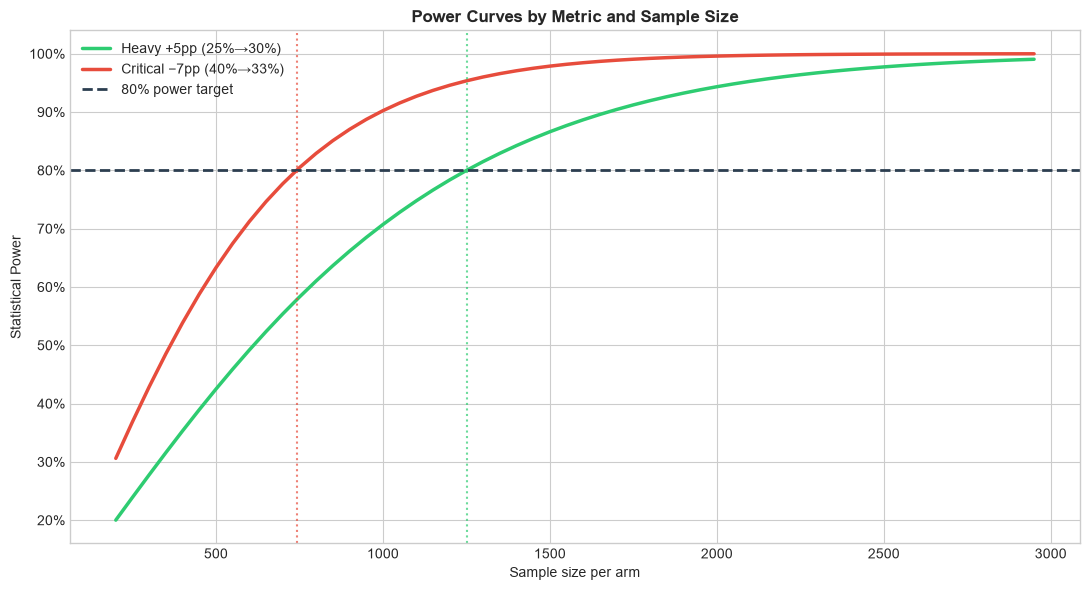

In [3]:
sample_sizes = np.arange(200, 3000, 50)

def compute_power(p1, p2, n, alpha=0.05):
    z_alpha = norm.ppf(1 - alpha/2)
    p_bar = (p1 + p2) / 2
    se_null = np.sqrt(2 * p_bar * (1 - p_bar) / n)
    se_alt  = np.sqrt((p1*(1-p1) + p2*(1-p2)) / n)
    effect  = abs(p1 - p2)
    return norm.cdf((effect - z_alpha * se_null) / se_alt)

power_heavy    = [compute_power(heavy_control, heavy_treatment, n) for n in sample_sizes]
power_critical = [compute_power(critical_control, critical_treatment, n) for n in sample_sizes]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(sample_sizes, power_heavy, linewidth=2.5, label='Heavy +5pp (25%→30%)', color='#2ecc71')
ax.plot(sample_sizes, power_critical, linewidth=2.5, label='Critical −7pp (40%→33%)', color='#e74c3c')
ax.axhline(0.80, color='#2c3e50', linestyle='--', linewidth=2, label='80% power target')
ax.axvline(n_heavy, color='#2ecc71', linestyle=':', linewidth=1.5, alpha=0.7)
ax.axvline(n_critical, color='#e74c3c', linestyle=':', linewidth=1.5, alpha=0.7)
ax.set_title('Power Curves by Metric and Sample Size', fontsize=12, fontweight='bold')
ax.set_xlabel('Sample size per arm')
ax.set_ylabel('Statistical Power')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend()
plt.tight_layout()
plt.show()

## 3. Simulate the A/B Experiment

In [4]:
df_ab = generate_ab_experiment(n_per_arm=2000, seed=42)
print(f'Experiment dataset: {len(df_ab):,} observations ({df_ab["arm"].value_counts().to_dict()})')
df_ab.head()

Experiment dataset: 4,000 observations ({'control': 2000, 'treatment': 2000})


,arm,d7_class,ltv,cac,converted
0,control,Critical,26.15,60.59,1
1,control,Moderate,108.67,64.06,1
2,control,Critical,19.47,68.05,1
3,control,Critical,22.90,55.41,1
4,control,Heavy,174.28,64.69,1


In [5]:
# D7 class mix by arm
mix_by_arm = df_ab.groupby(['arm', 'd7_class']).size().unstack(fill_value=0)
mix_pct = mix_by_arm.div(mix_by_arm.sum(axis=1), axis=0)
print('D7 Class Mix by Arm:')
print(mix_pct.map(lambda x: f'{x:.1%}'))

D7 Class Mix by Arm:
d7_class  Critical  Heavy Moderate
arm                               
control      40.2%  25.7%    34.1%
treatment    32.3%  30.0%    37.6%


## 4. Hypothesis Testing

In [6]:
def _proportions_ztest(counts, nobs, alternative='two-sided'):
    """Two-proportion z-test implemented via scipy.stats.norm."""
    p1 = counts[0] / nobs[0]
    p2 = counts[1] / nobs[1]
    p_pool = (counts[0] + counts[1]) / (nobs[0] + nobs[1])
    se = np.sqrt(p_pool * (1 - p_pool) * (1/nobs[0] + 1/nobs[1]))
    z = (p1 - p2) / se
    if alternative == 'larger':
        pval = norm.sf(z)
    elif alternative == 'smaller':
        pval = norm.cdf(z)
    else:
        pval = 2 * norm.sf(abs(z))
    return z, pval

for cls, direction in [('Heavy', 'increase'), ('Critical', 'decrease')]:
    control_n   = len(df_ab[df_ab['arm'] == 'control'])
    treatment_n = len(df_ab[df_ab['arm'] == 'treatment'])
    control_cls   = (df_ab[(df_ab['arm'] == 'control') & (df_ab['d7_class'] == cls)].shape[0])
    treatment_cls = (df_ab[(df_ab['arm'] == 'treatment') & (df_ab['d7_class'] == cls)].shape[0])

    p_control   = control_cls / control_n
    p_treatment = treatment_cls / treatment_n

    stat, pval = _proportions_ztest(
        [treatment_cls, control_cls], [treatment_n, control_n],
        alternative='larger' if direction == 'increase' else 'smaller'
    )
    result = '✅ REJECT H0' if pval < 0.05 else '⚠️ FAIL TO REJECT H0'
    print(f'{cls} share: control={p_control:.1%}, treatment={p_treatment:.1%} | p={pval:.4f} | {result}')

Heavy share: control=25.7%, treatment=30.0% | p=0.0010 | ✅ REJECT H0
Critical share: control=40.2%, treatment=32.3% | p=0.0000 | ✅ REJECT H0


## 5. Guardrail Checks

In [7]:
# CAC guardrail: treatment CPA ≤ +10% of control
avg_cac_control   = df_ab[df_ab['arm'] == 'control']['cac'].mean()
avg_cac_treatment = df_ab[df_ab['arm'] == 'treatment']['cac'].mean()
cpa_pct_change    = (avg_cac_treatment - avg_cac_control) / avg_cac_control
guardrail_cpa     = cpa_pct_change <= 0.10

print('Guardrail Checks:')
print(f'  CPA change: {cpa_pct_change:+.1%} | Threshold ≤+10% | {"✅ PASS" if guardrail_cpa else "❌ FAIL"}')

# Volume guardrail
vol_change = (len(df_ab[df_ab['arm'] == 'treatment']) - len(df_ab[df_ab['arm'] == 'control'])) / len(df_ab[df_ab['arm'] == 'control'])
guardrail_vol = vol_change >= -0.07
print(f'  Volume change: {vol_change:+.1%} | Threshold ≥-7% | {"✅ PASS" if guardrail_vol else "❌ FAIL"}')

print(f'\n  LTV improvement (treatment vs control): +{(df_ab[df_ab["arm"]=="treatment"]["ltv"].mean() - df_ab[df_ab["arm"]=="control"]["ltv"].mean()) / df_ab[df_ab["arm"]=="control"]["ltv"].mean():.1%}')

Guardrail Checks:
  CPA change: +6.3% | Threshold ≤+10% | ✅ PASS
  Volume change: +0.0% | Threshold ≥-7% | ✅ PASS

  LTV improvement (treatment vs control): +11.2%


## 6. Key Insight

The experiment is designed to be **conservative and fast**:
- Minimum 4 weeks to satisfy Meta's platform learning requirements (not driven by sample size)
- Guardrails prevent runaway CPA increases before the mix shift creates LTV gains
- A permanent 10% holdout ensures incrementality is measured continuously — not just at campaign level

**The break-even condition** is straightforward: the LTV gain from the mix shift must exceed the incremental CPA cost. At +5.7% LTV improvement with CPA +10%, the base scenario achieves positive ROI within 10 months.